In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from PIL import Image
import os

root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"

for folder, _, files in os.walk(root):
    for file in files:
        path = os.path.join(folder, file)
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            print("Deleting:", path)
            os.remove(path)

In [ ]:
import os
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch.utils.data import DataLoader, random_split
from torchvision.models import vit_b_16, ViT_B_16_Weights
from tqdm import tqdm
import pickle

# ------------------------
# Define ViT Binary Model
# ------------------------
class ViTBinary(nn.Module):
    def __init__(self):
        super().__init__()
        weights = ViT_B_16_Weights.DEFAULT
        self.model = vit_b_16(weights=weights)
        in_features = self.model.heads.head.in_features
        self.model.heads.head = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = ViT_B_16_Weights.DEFAULT
transform = ViT_B_16_Weights.DEFAULT.transforms()
model = ViTBinary().to(device)

data_dir = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"
checkpoint_dir = "/content/drive/MyDrive/Classification/Weights/ViT"

os.makedirs(checkpoint_dir, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

full_dataset = datasets.ImageFolder(root=data_dir, transform=transform)

# Split 80/20
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)

# ------------------------
# Loss & Optimizer
# ------------------------
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# ------------------------
# Training Setup
# ------------------------
num_epochs = 50

best_val_loss = float('inf')

history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print(f"Device: {device}")
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Total epochs: {num_epochs}")
print(f"Checkpoint directory: {checkpoint_dir}")



Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 182MB/s]


Device: cuda
Number of training samples: 2364
Number of validation samples: 591
Total epochs: 50
Checkpoint directory: /content/drive/MyDrive/Classification/Weights/ViT


In [ ]:
print(full_dataset.class_to_idx)

{'a_non_cancer': 0, 'b_cancer': 1}


In [ ]:
# ------------------------
# Training Loop
# ------------------------

for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):

    # ============================================================
    # TRAINING
    # ============================================================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * labels.size(0)

        # Predictions
        preds = (outputs > 0.5).float()

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    # Epoch training metrics
    train_loss = running_loss / total
    train_acc = correct / total


    # ============================================================
    # VALIDATION
    # ============================================================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            # Forward pass
            outputs = model(images)

            # Validation loss
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            # Predictions
            preds = (outputs > 0.5).float()

            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    # Epoch validation metrics
    val_loss /= val_total
    val_acc = val_correct / val_total


    # ============================================================
    # STORE HISTORY
    # ============================================================
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)


    # ============================================================
    # SAVE WEIGHTS AFTER EVERY EPOCH
    # ============================================================

    epoch_checkpoint_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_weights.pth"
    )

    torch.save(
        model.state_dict(),
        epoch_checkpoint_path
    )


    # ============================================================
    # SAVE COMPLETE CHECKPOINT
    # ============================================================
    # This is useful if you want to RESUME training later.

    epoch_checkpoint_full_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_checkpoint.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc
        },
        epoch_checkpoint_full_path
    )


    # ============================================================
    # SAVE BEST MODEL
    # ============================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_path = os.path.join(
            checkpoint_dir,
            "best_weights.pth"
        )

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            f"\n✅ New best model saved "
            f"(Epoch {epoch}, Val Loss = {val_loss:.4f})"
        )


    # ============================================================
    # SAVE TRAINING HISTORY AFTER EVERY EPOCH
    # ============================================================

    history_path = os.path.join(
        checkpoint_dir,
        "training_history.pkl"
    )

    with open(history_path, "wb") as f:
        pickle.dump(history, f)


    # ============================================================
    # PRINT EPOCH RESULTS
    # ============================================================

    print(
        f"Epoch {epoch:2d}: "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Acc: {train_acc:.4f}, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Acc: {val_acc:.4f}"
    )

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"All epoch weights saved in:")
print(checkpoint_dir)

Epochs:   0%|          | 0/50 [00:00<?, ?it/s]


✅ New best model saved (Epoch 1, Val Loss = 0.2086)


Epochs:   2%|▏         | 1/50 [02:03<1:41:07, 123.82s/it]

Epoch  1: Train Loss: 0.4136, Train Acc: 0.8012, Val Loss: 0.2086, Val Acc: 0.9255


Epochs:   4%|▍         | 2/50 [04:16<1:43:07, 128.91s/it]

...

Epoch 48: Train Loss: 0.0000, Train Acc: 1.0000, Val Loss: 0.4584, Val Acc: 0.9239


Epochs:  98%|█████████▊| 49/50 [1:55:01<02:16, 136.23s/it]

Epoch 49: Train Loss: 0.0000, Train Acc: 1.0000, Val Loss: 0.4610, Val Acc: 0.9239


Epochs: 100%|██████████| 50/50 [1:57:23<00:00, 140.86s/it]

Epoch 50: Train Loss: 0.0000, Train Acc: 1.0000, Val Loss: 0.4636, Val Acc: 0.9239

TRAINING COMPLETED
Best Validation Loss: 0.1984
All epoch weights saved in:
/content/drive/MyDrive/Classification/Weights/ViT


In [ ]:
import os
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch.utils.data import DataLoader, random_split
from torchvision.models import vit_b_16, ViT_B_16_Weights
from tqdm import tqdm
import pickle
import os
import torch
import torch.nn as nn
from torchvision.models.swin_transformer import swin_t, Swin_T_Weights
from torchvision.io import read_image
from torchvision.transforms import functional as TF
import pandas as pd
from tqdm import tqdm
import numpy as np

# ----------------------

# ------------------------
# Define ViT Binary Model
# ------------------------
class ViTBinary(nn.Module):
    def __init__(self):
        super().__init__()
        weights = ViT_B_16_Weights.DEFAULT
        self.model = vit_b_16(weights=weights)
        in_features = self.model.heads.head.in_features
        self.model.heads.head = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = ViT_B_16_Weights.DEFAULT
transform = ViT_B_16_Weights.DEFAULT.transforms()


model = ViTBinary().to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/Classification/Weights/ViT/epoch_06_weights.pth"))  # ← replace with your path
model.eval()

# ----------------------
# Test folders
# ----------------------
test_root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Testing_resized_v2"
class_map = {'a_non_cancer': 0, 'b_cancer': 1}

# ----------------------
# Evaluation Loop
# ----------------------
TP = FP = TN = FN = 0
accuracies = []

with torch.no_grad():
    for cls_name, label in class_map.items():
        folder = os.path.join(test_root, cls_name)
        for fname in tqdm(os.listdir(folder), desc=f"Evaluating {cls_name}"):
            if not fname.lower().endswith(('.png', '.jpg', '.jpeg')): continue

            path = os.path.join(folder, fname)
            image = read_image(path).float() / 255.0
            image = transform(image).unsqueeze(0).to(device)

            output = model(image)
            pred = 1 if output.item() > 0.5 else 0

            # Accuracy for deviation
            correct = (pred == label)
            accuracies.append(int(correct))

            # Confusion matrix components
            if pred == 1 and label == 1:
                TP += 1
            elif pred == 1 and label == 0:
                FP += 1
            elif pred == 0 and label == 0:
                TN += 1
            elif pred == 0 and label == 1:
                FN += 1

# ----------------------
# Metrics
# ----------------------
total = TP + FP + TN + FN
accuracy = (TP + TN) / total if total else 0
sensitivity = TP / (TP + FN) if (TP + FN) else 0
specificity = TN / (TN + FP) if (TN + FP) else 0
deviation = np.std(accuracies)

# ----------------------
# Save CSV
# ----------------------
results = {
    'TP': [TP],
    'FP': [FP],
    'TN': [TN],
    'FN': [FN],
    'Accuracy': [round(accuracy, 4)],
    'Sensitivity': [round(sensitivity, 4)],
    'Specificity': [round(specificity, 4)],
    'Accuracy StdDev': [round(deviation, 4)]
}

df = pd.DataFrame(results)
df.to_csv("/content/drive/MyDrive/Classification/Results/ViT/Vit_epoch6.csv", index=False)
print("\n✅ Results saved to 'Vit_epoch6.csv'")


Evaluating b_cancer: 100%|██████████| 164/164 [00:02<00:00, 56.46it/s]



✅ Results saved to 'Vit_epoch6.csv'


DEVICE
cuda

Loading ViT weights:
/content/drive/MyDrive/Classification/Weights/ViT/epoch_06_weights.pth
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 130MB/s]



✅ ViT model loaded successfully.


STARTING ViT TEST EVALUATION


Evaluating b_cancer: 100%|██████████| 164/164 [00:05<00:00, 28.94it/s]




ViT-B/16 TEST RESULTS
Total Images Tested: 328

Confusion Matrix:
  True Positives (TP):   146
  False Positives (FP):  8
  True Negatives (TN):   156
  False Negatives (FN):  18

Performance Metrics:
  Accuracy:              0.9207 (92.07%)
  Sensitivity:           0.8902 (89.02%)
  Specificity:           0.9512 (95.12%)
  Precision:             0.9481 (94.81%)
  F1-Score:              0.9182
  Accuracy StdDev:       0.2702

95% Confidence Intervals:
  Accuracy CI:           [0.8864, 0.9453]
  Sensitivity CI:        [0.8332, 0.9294]
  Specificity CI:        [0.9067, 0.9751]
  Precision CI:          [0.9008, 0.9734]
  F1-Score CI:           [0.8853, 0.9481]

Calibration Metrics:
  Brier Score:           0.072940
  ECE:                   0.500297
  MCE:                   0.919818


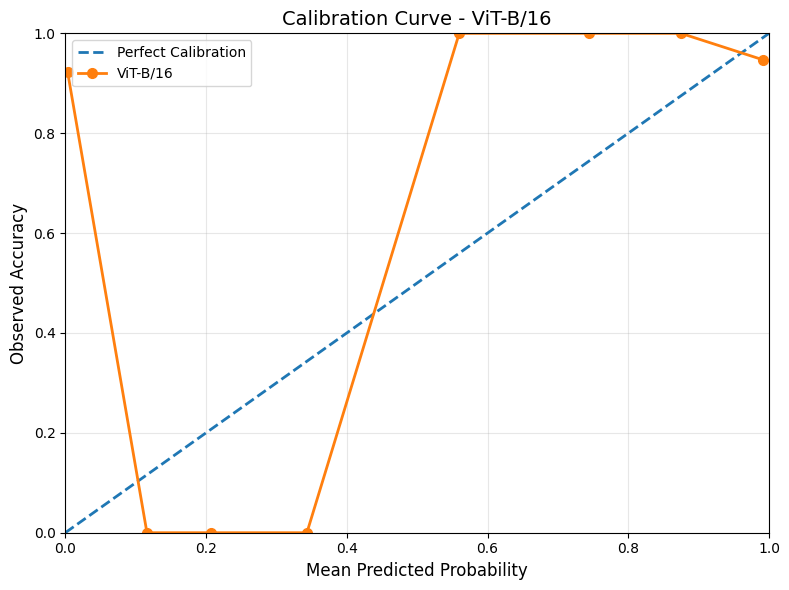

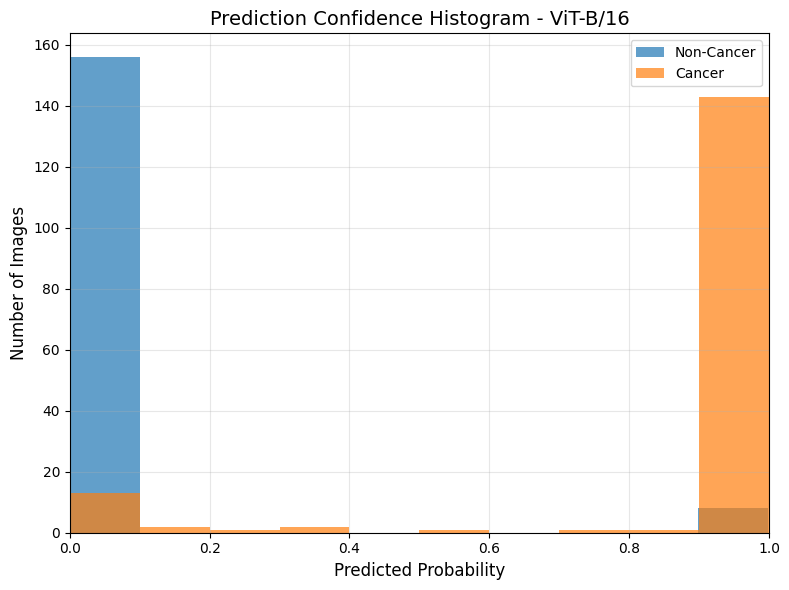

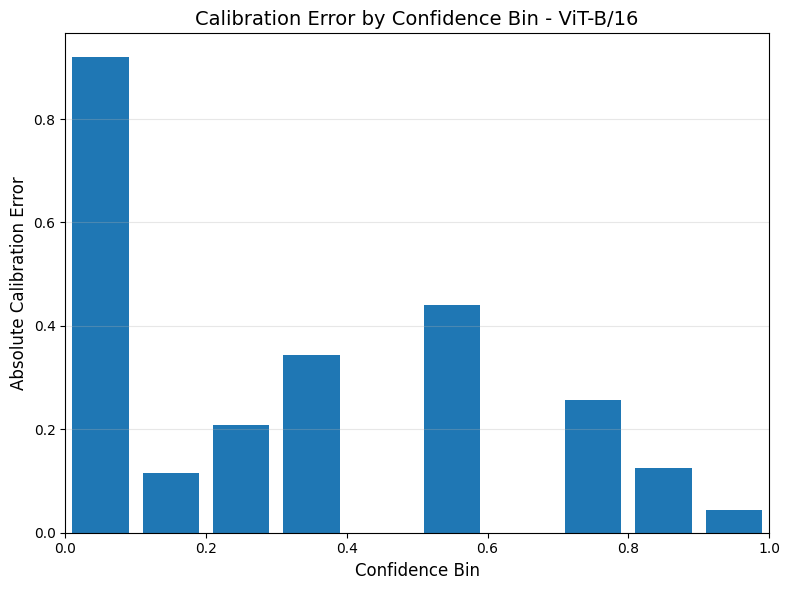

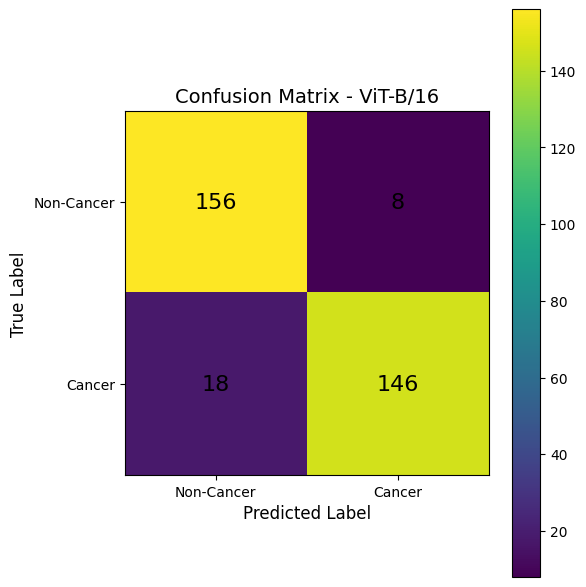



FILES SAVED

Main metrics:
/content/drive/MyDrive/Classification/Results/ViT/Calibration_analysis/Vit_epoch6_ALL_METRICS.csv

Calibration bins:
/content/drive/MyDrive/Classification/Results/ViT/Calibration_analysis/Vit_epoch6_calibration_bins.csv

Detailed predictions:
/content/drive/MyDrive/Classification/Results/ViT/Calibration_analysis/Vit_epoch6_detailed_predictions.csv

Calibration curve:
/content/drive/MyDrive/Classification/Results/ViT/Calibration_analysis/Calibration_Plots/Vit_epoch6_calibration_curve.png

Confidence histogram:
/content/drive/MyDrive/Classification/Results/ViT/Calibration_analysis/Calibration_Plots/Vit_epoch6_confidence_histogram.png

Calibration error:
/content/drive/MyDrive/Classification/Results/ViT/Calibration_analysis/Calibration_Plots/Vit_epoch6_calibration_error.png

Confusion matrix:
/content/drive/MyDrive/Classification/Results/ViT/Calibration_analysis/Calibration_Plots/Vit_epoch6_confusion_matrix.png

ViT CALIBRATION ANALYSIS COMPLETE


In [2]:
# ============================================================
# ViT-B/16
# PERFORMANCE + CALIBRATION METRICS
# ============================================================

import os
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from torchvision.models import vit_b_16, ViT_B_16_Weights
from torchvision.io import read_image
from tqdm import tqdm


# ============================================================
# 1. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("DEVICE")
print("=" * 70)
print(device)


# ============================================================
# 2. ViT B/16 BINARY MODEL
# ============================================================

class ViTBinary(nn.Module):

    def __init__(self):

        super().__init__()

        weights = ViT_B_16_Weights.DEFAULT

        self.model = vit_b_16(
            weights=weights
        )

        in_features = (
            self.model.heads.head.in_features
        )

        self.model.heads.head = nn.Sequential(
            nn.Linear(
                in_features,
                1
            ),
            nn.Sigmoid()
        )

    def forward(self, x):

        return self.model(x)


# ============================================================
# 3. LOAD MODEL
# ============================================================

weights_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "ViT/"
    "epoch_06_weights.pth"
)

print("\nLoading ViT weights:")
print(weights_path)

model = ViTBinary().to(device)

checkpoint = torch.load(
    weights_path,
    map_location=device
)


# ------------------------------------------------------------
# Handle checkpoint formats
# ------------------------------------------------------------

if (
    isinstance(checkpoint, dict)
    and "state_dict" in checkpoint
):

    checkpoint = checkpoint["state_dict"]

elif (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):

    checkpoint = checkpoint["model_state_dict"]


# ------------------------------------------------------------
# Remove module. prefix if present
# ------------------------------------------------------------

clean_checkpoint = {}

for key, value in checkpoint.items():

    new_key = key

    if new_key.startswith("module."):

        new_key = new_key[7:]

    clean_checkpoint[new_key] = value


# ------------------------------------------------------------
# Load weights
# ------------------------------------------------------------

missing_keys, unexpected_keys = (
    model.load_state_dict(
        clean_checkpoint,
        strict=False
    )
)

if missing_keys:

    print("\nMissing keys:")
    print(missing_keys[:10])

if unexpected_keys:

    print("\nUnexpected keys:")
    print(unexpected_keys[:10])


model.eval()

print("\n✅ ViT model loaded successfully.")


# ============================================================
# 4. TRANSFORM
# ============================================================

weights = ViT_B_16_Weights.DEFAULT

transform = weights.transforms()


# ============================================================
# 5. TEST DATA
# ============================================================

test_root = (
    "/content/drive/MyDrive/"
    "Classification/Bt_training_and_testing/"
    "Testing_resized_v2"
)

class_map = {
    "a_non_cancer": 0,
    "b_cancer": 1
}


# ============================================================
# 6. OUTPUT DIRECTORIES
# ============================================================

output_dir = (
    "/content/drive/MyDrive/"
    "Classification/Results/"
    "ViT/Calibration_analysis"
)

plot_dir = os.path.join(
    output_dir,
    "Calibration_Plots"
)

os.makedirs(
    output_dir,
    exist_ok=True
)

os.makedirs(
    plot_dir,
    exist_ok=True
)


# ============================================================
# 7. STORAGE
# ============================================================

TP = 0
FP = 0
TN = 0
FN = 0

accuracies = []

all_probabilities = []
all_predictions = []
all_labels = []
all_filenames = []


# ============================================================
# 8. EVALUATION LOOP
# ============================================================

print("\n")
print("=" * 70)
print("STARTING ViT TEST EVALUATION")
print("=" * 70)


with torch.no_grad():

    for cls_name, label in class_map.items():

        folder = os.path.join(
            test_root,
            cls_name
        )

        if not os.path.exists(folder):

            print(
                f"WARNING: Folder does not exist: {folder}"
            )

            continue

        filenames = sorted(
            os.listdir(folder)
        )

        for fname in tqdm(
            filenames,
            desc=f"Evaluating {cls_name}"
        ):

            if not fname.lower().endswith(
                (
                    ".png",
                    ".jpg",
                    ".jpeg"
                )
            ):

                continue

            path = os.path.join(
                folder,
                fname
            )

            try:

                # ------------------------------------------------
                # Read image
                # ------------------------------------------------

                image = (
                    read_image(path)
                    .float()
                    / 255.0
                )

                # ------------------------------------------------
                # EXACT SAME preprocessing
                # ------------------------------------------------

                image = transform(
                    image
                )

                image = (
                    image
                    .unsqueeze(0)
                    .to(device)
                )

                # ------------------------------------------------
                # Prediction
                # ------------------------------------------------

                output = model(image)

                probability = output.item()

                # ------------------------------------------------
                # EXACT SAME 0.5 threshold
                # ------------------------------------------------

                pred = (
                    1
                    if probability > 0.5
                    else 0
                )

                # ------------------------------------------------
                # Store probabilities
                # ------------------------------------------------

                all_probabilities.append(
                    probability
                )

                all_predictions.append(
                    pred
                )

                all_labels.append(
                    label
                )

                all_filenames.append(
                    fname
                )

                # ------------------------------------------------
                # Accuracy deviation
                # ------------------------------------------------

                correct = (
                    pred == label
                )

                accuracies.append(
                    int(correct)
                )

                # ------------------------------------------------
                # Confusion matrix
                # ------------------------------------------------

                if pred == 1 and label == 1:

                    TP += 1

                elif pred == 1 and label == 0:

                    FP += 1

                elif pred == 0 and label == 0:

                    TN += 1

                elif pred == 0 and label == 1:

                    FN += 1

            except Exception as e:

                print(
                    f"\nError processing {fname}: {e}"
                )

                continue


# ============================================================
# 9. CONVERT TO NUMPY
# ============================================================

probabilities = np.asarray(
    all_probabilities,
    dtype=np.float64
)

predictions = np.asarray(
    all_predictions,
    dtype=np.int64
)

labels = np.asarray(
    all_labels,
    dtype=np.int64
)

accuracies = np.asarray(
    accuracies,
    dtype=np.float64
)


# ============================================================
# 10. BASIC PERFORMANCE METRICS
# ============================================================

total = (
    TP +
    FP +
    TN +
    FN
)

# EXACT FORMULA PROVIDED BY YOU

accuracy = (
    (TP + TN) / total
    if total
    else 0
)

sensitivity = (
    TP / (TP + FN)
    if (TP + FN)
    else 0
)

specificity = (
    TN / (TN + FP)
    if (TN + FP)
    else 0
)

precision = (
    TP / (TP + FP)
    if (TP + FP)
    else 0
)

f1_score = (
    2 *
    precision *
    sensitivity /
    (precision + sensitivity)
    if (
        precision +
        sensitivity
    )
    else 0
)

deviation = (
    np.std(accuracies)
    if len(accuracies)
    else 0
)


# ============================================================
# 11. WILSON 95% CONFIDENCE INTERVAL
# ============================================================

def wilson_ci(
    successes,
    n,
    confidence=0.95
):

    if n == 0:

        return 0.0, 0.0

    z = 1.959963984540054

    p = successes / n

    denominator = (
        1 +
        (z ** 2 / n)
    )

    center = (
        p +
        (z ** 2 / (2 * n))
    ) / denominator

    margin = (
        z *
        np.sqrt(
            (
                p * (1 - p) / n
            )
            +
            (
                z ** 2 /
                (4 * n ** 2)
            )
        )
        / denominator
    )

    lower = max(
        0,
        center - margin
    )

    upper = min(
        1,
        center + margin
    )

    return lower, upper


# ============================================================
# 12. CONFIDENCE INTERVALS
# ============================================================

accuracy_ci_low, accuracy_ci_high = wilson_ci(
    TP + TN,
    total
)

sensitivity_ci_low, sensitivity_ci_high = wilson_ci(
    TP,
    TP + FN
)

specificity_ci_low, specificity_ci_high = wilson_ci(
    TN,
    TN + FP
)

precision_ci_low, precision_ci_high = wilson_ci(
    TP,
    TP + FP
)


# ============================================================
# 13. F1 95% CI USING BOOTSTRAPPING
# ============================================================

def calculate_f1(
    y_true,
    y_pred
):

    tp = np.sum(
        (y_true == 1) &
        (y_pred == 1)
    )

    fp = np.sum(
        (y_true == 0) &
        (y_pred == 1)
    )

    fn = np.sum(
        (y_true == 1) &
        (y_pred == 0)
    )

    p = (
        tp / (tp + fp)
        if (tp + fp)
        else 0
    )

    r = (
        tp / (tp + fn)
        if (tp + fn)
        else 0
    )

    if p + r == 0:

        return 0

    return (
        2 * p * r /
        (p + r)
    )


def bootstrap_f1_ci(
    y_true,
    y_pred,
    n_bootstrap=2000,
    seed=42
):

    if len(y_true) == 0:

        return 0, 0

    rng = np.random.default_rng(
        seed
    )

    n = len(y_true)

    f1_values = []

    for _ in range(
        n_bootstrap
    ):

        indices = rng.integers(
            0,
            n,
            size=n
        )

        f1_values.append(
            calculate_f1(
                y_true[indices],
                y_pred[indices]
            )
        )

    lower = np.percentile(
        f1_values,
        2.5
    )

    upper = np.percentile(
        f1_values,
        97.5
    )

    return lower, upper


f1_ci_low, f1_ci_high = (
    bootstrap_f1_ci(
        labels,
        predictions
    )
)


# ============================================================
# 14. BRIER SCORE
# ============================================================

brier_score = np.mean(
    (
        probabilities -
        labels
    ) ** 2
)


# ============================================================
# 15. CALIBRATION BINS
# ============================================================

n_bins = 10

bin_edges = np.linspace(
    0,
    1,
    n_bins + 1
)

bin_centers = []
bin_counts = []
bin_confidences = []
bin_accuracies = []
bin_errors = []


for i in range(n_bins):

    lower = bin_edges[i]

    upper = bin_edges[i + 1]

    if i == n_bins - 1:

        mask = (
            (probabilities >= lower) &
            (probabilities <= upper)
        )

    else:

        mask = (
            (probabilities >= lower) &
            (probabilities < upper)
        )

    count = np.sum(mask)

    if count == 0:

        continue

    mean_confidence = np.mean(
        probabilities[mask]
    )

    observed_accuracy = np.mean(
        labels[mask] ==
        predictions[mask]
    )

    absolute_error = abs(
        observed_accuracy -
        mean_confidence
    )

    bin_centers.append(
        (lower + upper) / 2
    )

    bin_counts.append(
        count
    )

    bin_confidences.append(
        mean_confidence
    )

    bin_accuracies.append(
        observed_accuracy
    )

    bin_errors.append(
        absolute_error
    )


bin_centers = np.asarray(
    bin_centers
)

bin_counts = np.asarray(
    bin_counts
)

bin_confidences = np.asarray(
    bin_confidences
)

bin_accuracies = np.asarray(
    bin_accuracies
)

bin_errors = np.asarray(
    bin_errors
)


# ============================================================
# 16. ECE
# ============================================================

if total > 0:

    ECE = np.sum(
        (
            bin_counts /
            total
        ) *
        bin_errors
    )

else:

    ECE = 0


# ============================================================
# 17. MCE
# ============================================================

if len(bin_errors) > 0:

    MCE = np.max(
        bin_errors
    )

else:

    MCE = 0


# ============================================================
# 18. CALIBRATION TABLE
# ============================================================

calibration_df = pd.DataFrame({

    "Bin Center":
        bin_centers,

    "Bin Count":
        bin_counts,

    "Mean Confidence":
        bin_confidences,

    "Observed Accuracy":
        bin_accuracies,

    "Absolute Calibration Error":
        bin_errors
})


calibration_csv = os.path.join(
    output_dir,
    "Vit_epoch6_calibration_bins.csv"
)

calibration_df.to_csv(
    calibration_csv,
    index=False
)


# ============================================================
# 19. PRINT ALL RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("ViT-B/16 TEST RESULTS")
print("=" * 70)

print(
    f"Total Images Tested: {total}"
)

print("\nConfusion Matrix:")

print(
    f"  True Positives (TP):   {TP}"
)

print(
    f"  False Positives (FP):  {FP}"
)

print(
    f"  True Negatives (TN):   {TN}"
)

print(
    f"  False Negatives (FN):  {FN}"
)


print("\nPerformance Metrics:")

print(
    f"  Accuracy:              "
    f"{accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"  Sensitivity:           "
    f"{sensitivity:.4f} "
    f"({sensitivity * 100:.2f}%)"
)

print(
    f"  Specificity:           "
    f"{specificity:.4f} "
    f"({specificity * 100:.2f}%)"
)

print(
    f"  Precision:             "
    f"{precision:.4f} "
    f"({precision * 100:.2f}%)"
)

print(
    f"  F1-Score:              "
    f"{f1_score:.4f}"
)

print(
    f"  Accuracy StdDev:       "
    f"{deviation:.4f}"
)


print("\n95% Confidence Intervals:")

print(
    f"  Accuracy CI:           "
    f"[{accuracy_ci_low:.4f}, "
    f"{accuracy_ci_high:.4f}]"
)

print(
    f"  Sensitivity CI:        "
    f"[{sensitivity_ci_low:.4f}, "
    f"{sensitivity_ci_high:.4f}]"
)

print(
    f"  Specificity CI:        "
    f"[{specificity_ci_low:.4f}, "
    f"{specificity_ci_high:.4f}]"
)

print(
    f"  Precision CI:          "
    f"[{precision_ci_low:.4f}, "
    f"{precision_ci_high:.4f}]"
)

print(
    f"  F1-Score CI:           "
    f"[{f1_ci_low:.4f}, "
    f"{f1_ci_high:.4f}]"
)


print("\nCalibration Metrics:")

print(
    f"  Brier Score:           "
    f"{brier_score:.6f}"
)

print(
    f"  ECE:                   "
    f"{ECE:.6f}"
)

print(
    f"  MCE:                   "
    f"{MCE:.6f}"
)

print("=" * 70)


# ============================================================
# 20. CALIBRATION / RELIABILITY CURVE
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Perfect Calibration"
)

plt.plot(
    bin_confidences,
    bin_accuracies,
    marker="o",
    linewidth=2,
    markersize=7,
    label="ViT-B/16"
)

plt.xlabel(
    "Mean Predicted Probability",
    fontsize=12
)

plt.ylabel(
    "Observed Accuracy",
    fontsize=12
)

plt.title(
    "Calibration Curve - ViT-B/16",
    fontsize=14
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

calibration_plot = os.path.join(
    plot_dir,
    "Vit_epoch6_calibration_curve.png"
)

plt.savefig(
    calibration_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 21. CONFIDENCE HISTOGRAM
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.hist(
    probabilities[labels == 0],
    bins=10,
    alpha=0.7,
    label="Non-Cancer"
)

plt.hist(
    probabilities[labels == 1],
    bins=10,
    alpha=0.7,
    label="Cancer"
)

plt.xlabel(
    "Predicted Probability",
    fontsize=12
)

plt.ylabel(
    "Number of Images",
    fontsize=12
)

plt.title(
    "Prediction Confidence Histogram - ViT-B/16",
    fontsize=14
)

plt.xlim(
    0,
    1
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

histogram_plot = os.path.join(
    plot_dir,
    "Vit_epoch6_confidence_histogram.png"
)

plt.savefig(
    histogram_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 22. CALIBRATION ERROR BY BIN
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.bar(
    bin_centers,
    bin_errors,
    width=0.08,
    align="center"
)

plt.xlabel(
    "Confidence Bin",
    fontsize=12
)

plt.ylabel(
    "Absolute Calibration Error",
    fontsize=12
)

plt.title(
    "Calibration Error by Confidence Bin - ViT-B/16",
    fontsize=14
)

plt.xlim(
    0,
    1
)

plt.grid(
    True,
    axis="y",
    alpha=0.3
)

plt.tight_layout()

error_plot = os.path.join(
    plot_dir,
    "Vit_epoch6_calibration_error.png"
)

plt.savefig(
    error_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 23. CONFUSION MATRIX
# ============================================================

cm = np.array([
    [TN, FP],
    [FN, TP]
])


plt.figure(
    figsize=(6, 6)
)

plt.imshow(
    cm
)

plt.title(
    "Confusion Matrix - ViT-B/16",
    fontsize=14
)

plt.colorbar()

plt.xticks(
    [0, 1],
    [
        "Non-Cancer",
        "Cancer"
    ]
)

plt.yticks(
    [0, 1],
    [
        "Non-Cancer",
        "Cancer"
    ]
)

plt.xlabel(
    "Predicted Label",
    fontsize=12
)

plt.ylabel(
    "True Label",
    fontsize=12
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=16
        )

plt.tight_layout()

cm_plot = os.path.join(
    plot_dir,
    "Vit_epoch6_confusion_matrix.png"
)

plt.savefig(
    cm_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 24. SAVE MAIN METRICS CSV
# ============================================================

results = {

    "Model": [
        "ViT-B/16"
    ],

    "TP": [TP],

    "FP": [FP],

    "TN": [TN],

    "FN": [FN],

    "Total": [total],

    "Accuracy": [
        round(
            accuracy,
            4
        )
    ],

    "Sensitivity": [
        round(
            sensitivity,
            4
        )
    ],

    "Specificity": [
        round(
            specificity,
            4
        )
    ],

    "Precision": [
        round(
            precision,
            4
        )
    ],

    "F1-Score": [
        round(
            f1_score,
            4
        )
    ],

    "Accuracy StdDev": [
        round(
            deviation,
            4
        )
    ],

    "Accuracy CI Lower": [
        round(
            accuracy_ci_low,
            4
        )
    ],

    "Accuracy CI Upper": [
        round(
            accuracy_ci_high,
            4
        )
    ],

    "Sensitivity CI Lower": [
        round(
            sensitivity_ci_low,
            4
        )
    ],

    "Sensitivity CI Upper": [
        round(
            sensitivity_ci_high,
            4
        )
    ],

    "Specificity CI Lower": [
        round(
            specificity_ci_low,
            4
        )
    ],

    "Specificity CI Upper": [
        round(
            specificity_ci_high,
            4
        )
    ],

    "Precision CI Lower": [
        round(
            precision_ci_low,
            4
        )
    ],

    "Precision CI Upper": [
        round(
            precision_ci_high,
            4
        )
    ],

    "F1 CI Lower": [
        round(
            f1_ci_low,
            4
        )
    ],

    "F1 CI Upper": [
        round(
            f1_ci_high,
            4
        )
    ],

    "Brier Score": [
        round(
            brier_score,
            6
        )
    ],

    "ECE": [
        round(
            ECE,
            6
        )
    ],

    "MCE": [
        round(
            MCE,
            6
        )
    ]
}


results_df = pd.DataFrame(
    results
)


results_csv = os.path.join(
    output_dir,
    "Vit_epoch6_ALL_METRICS.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)


# ============================================================
# 25. SAVE DETAILED PREDICTIONS
# ============================================================

detailed_df = pd.DataFrame({

    "Filename":
        all_filenames,

    "True_Label":
        all_labels,

    "Predicted_Label":
        all_predictions,

    "Predicted_Probability":
        all_probabilities,

    "Correct":
        [
            int(
                p == l
            )
            for p, l in zip(
                all_predictions,
                all_labels
            )
        ]
})


detailed_csv = os.path.join(
    output_dir,
    "Vit_epoch6_detailed_predictions.csv"
)

detailed_df.to_csv(
    detailed_csv,
    index=False
)


# ============================================================
# 26. FINAL FILE LOCATIONS
# ============================================================

print("\n")
print("=" * 70)
print("FILES SAVED")
print("=" * 70)

print(
    "\nMain metrics:"
)

print(
    results_csv
)

print(
    "\nCalibration bins:"
)

print(
    calibration_csv
)

print(
    "\nDetailed predictions:"
)

print(
    detailed_csv
)

print(
    "\nCalibration curve:"
)

print(
    calibration_plot
)

print(
    "\nConfidence histogram:"
)

print(
    histogram_plot
)

print(
    "\nCalibration error:"
)

print(
    error_plot
)

print(
    "\nConfusion matrix:"
)

print(
    cm_plot
)

print("\n" + "=" * 70)
print("ViT CALIBRATION ANALYSIS COMPLETE")
print("=" * 70)